In [1]:
%load_ext autoreload
%autoreload 2

# Device selection

In [2]:
from cobos.tokens import ibm_token, group_instance, group_instance2
from qiskit_ibm_runtime import QiskitRuntimeService

channel = "ibm_quantum"
# device = "ibm_fez"
# device = "ibm_sherbrooke"
# device = "ibm_torino"
device = "ibm_marrakesh"
# device = "ibm_aachen"
# device = "ibm_kingston"

service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)
backend = service.backend(device)

/var/folders/t9/xqv32vzn2pb091tj9_rz1_zh0000gn/T/ipykernel_9252/664675149.py:12: DeprecationWarning: The "ibm_quantum" channel option is deprecated and will be sunset on 1 July. After this date, ibm_cloud will be the only valid channel. For information on migrating to the new IBM Quantum Platform on the "ibm_cloud" channel, review the migration guide https://quantum.cloud.ibm.com/docs/migration-guides/classic-iqp-to-cloud-iqp .
  service = QiskitRuntimeService(channel=channel, token=ibm_token, instance=group_instance2)


# Auxiliary lattice plot

18 possible layouts


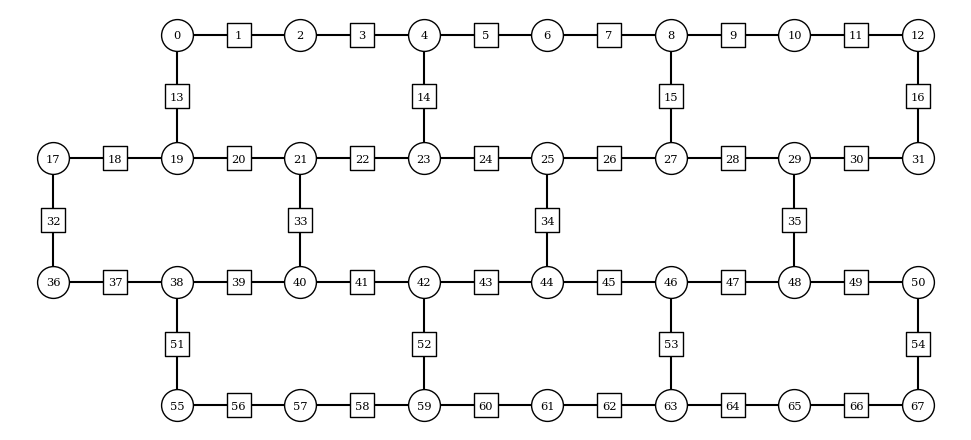

In [3]:
from z2hex.geometry import HeavyHexLattice

plaquette_width = 3
plaquette_height = 3

lattice = HeavyHexLattice(plaquette_width, plaquette_height)
nlayouts = len(lattice.get_all_layouts(backend))
print(f"{nlayouts} possible layouts")
lattice.plot_lattice(number_qubits=True)

# Simulation settings

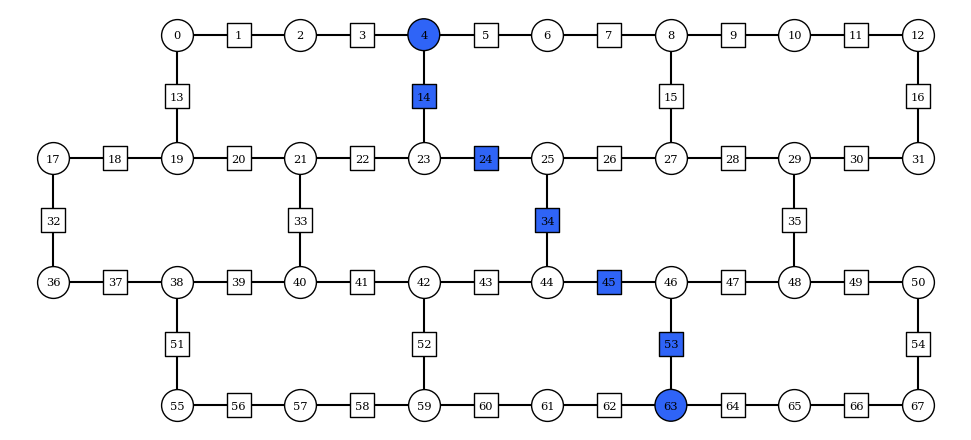

In [4]:
from z2hex.gdd import random, constant, counteract_rotation, zero_mean
from utils.hexec import create_estimator_options
from utils.execrecord import ExecutionRecord
from utils.hexec import ExecDB
from functools import partial

lattice_dims = (plaquette_width, plaquette_height)
J = 0.3
h = 0.5
lamb = 1

x_basis = False

fractional_gates = False

# string = [27, 26, 34, 43, 52, 60, 59]
# string = [4, 10, 17, 24, 30]
string = [4, 14, 24, 34, 45, 53, 63]
# string = [21, 33, 41, 52, 62, 72, 83, 91, 103]
# string = [4, 10, 18, 17, 16, 24, 30, 15, 14, 19, 20]
# string = [1, 2, 9, 15, 19, 16, 17, 21, 22, 24, 26, 27, 29]

# string = [21, 33, 41, 52, 62, 72, 83, 91, 104, 111, 124]
# string = [27, 26, 24, 22, 33, 41, 43, 45, 53, 64, 62, 60, 71, 79, 81, 83, 91, 102, 100, 98, 109, 117, 119, 121, 122] # Benchmark
# string = []

final_time = 4.5
dt = 0.15
steps = 30
desired_error = 1e-2

confidence = 0.9

cal = True
postselect_odr = True
flip_threshold = 1
all_or_first_layout_qubit = None
forbidden_qubits = []
max_layouts = 4
recovery = True
# g_func = None
# g_func = partial(counteract_rotation, ham_param=J)
# g_func = partial(constant, angle=np.pi)
# g_func = random
g_func = zero_mean

pt_num_randomizations = 240
pt_shots_per_randomization = 2000

shots = pt_num_randomizations * pt_shots_per_randomization
max_shots = 100000
# shots = 75000
# max_shots = 75000

final_twirl_randomizations = pt_num_randomizations
if shots > max_shots:
    final_twirl_randomizations = int(final_twirl_randomizations * max_shots / shots)
if all_or_first_layout_qubit == True:
    final_twirl_randomizations = int(final_twirl_randomizations/max_layouts)
if final_twirl_randomizations < 1:
    final_twirl_randomizations = 1

sampler_options = {
    "default_shots": shots,
    "execution": {
        "init_qubits": True,
        "meas_type": "classified"
    },
    "dynamical_decoupling": {
        "enable": False,
        "sequence_type": "XY4"
    },
    "twirling": {
        "enable_gates": True,
        "enable_measure": True,
        "num_randomizations": final_twirl_randomizations,
        "shots_per_randomization": pt_shots_per_randomization
    }
}

# execution_database = "z2_hex_jobs_dec.json" # Last db with good jobs / Not in the new order
execution_database = "z2_hex_jobs.json"
jobs_result_folder = execution_database.split(".")[0] + "/"
job_db = ExecDB(execution_database)

circ_folder_path = "Circuits/"

execution_record_path = "../../../../Executions_record.xlsx"
execrecord = ExecutionRecord(execution_record_path)

lattice.plot_highlighted_qubits(string, colors=["#2f64f7"]*len(string), number_qubits=True)

# Error guarantees

In [5]:
from z2hex.geometry import HeavyHexLattice
from z2hex.circs import trotter_dt
import numpy as np

lattice = HeavyHexLattice(*lattice_dims)

error_dt = trotter_dt(desired_error, lattice, J, h, lamb)
nsteps = np.ceil(final_time / error_dt)

print(f"With provided the hardware error Δt should be:\nΔt = {error_dt:.5f}")
print(f"To correctly reach the desired final time, the number of layers required is:\nN = {nsteps} ({nsteps*6} 2Qb depth)")

With provided the hardware error Δt should be:
Δt = 0.06651
To correctly reach the desired final time, the number of layers required is:
N = 68 (408 2Qb depth)


In [6]:
from z2hex.circs import trotter_error

lattice = HeavyHexLattice(*lattice_dims)

settings_error = trotter_error(dt, lattice, J, h, lamb)
sim_max_nlayers = np.ceil(final_time // dt).astype(int)

print(f"With the current simultation settings Δt is at most\nΔt = {dt:.5f}")
print(f"The error per layer commited in the wrost case is\nƐ = {settings_error:.05}")
print(f"The number of layers at the final evolution time is\nN = {sim_max_nlayers} ({6*sim_max_nlayers} 2Qb depth)")

With the current simultation settings Δt is at most
Δt = 0.15000
The error per layer commited in the wrost case is
Ɛ = 0.11474
The number of layers at the final evolution time is
N = 30 (180 2Qb depth)


# Record tools

## Add separator

In [7]:
# execrecord.add_separator()

# Circuit generation & observables

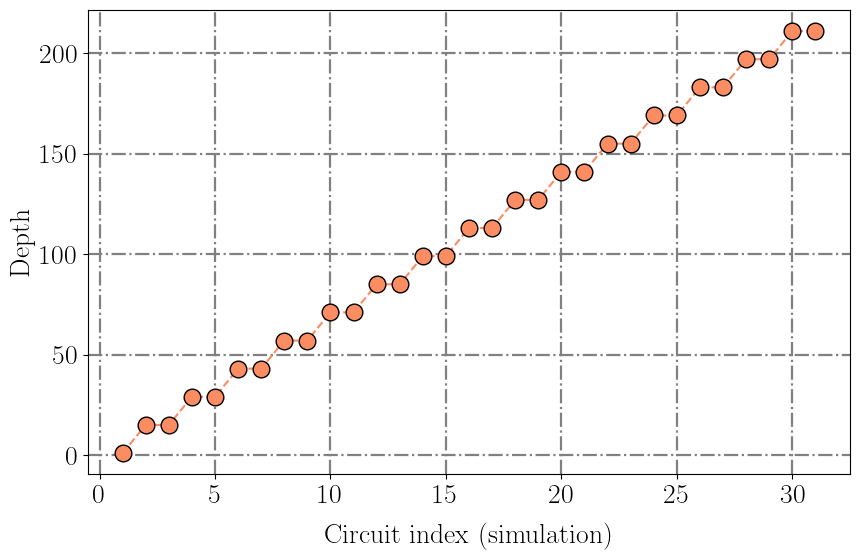

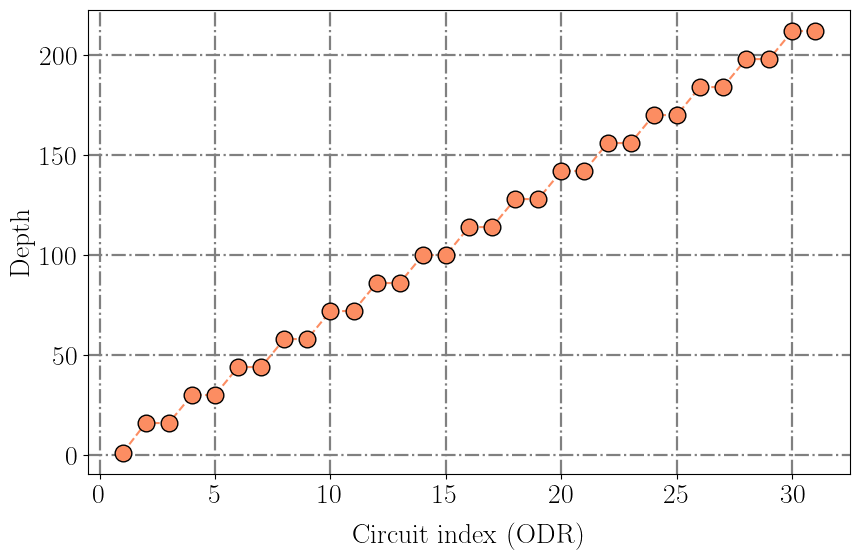

In [8]:
from z2hex.circs import string_quench_simulation_circuits_dt, simulation_and_odr_circuits, simulation_and_odr_circuits_2t, get_layouts
from z2hex.geometry import HeavyHexLattice, sort_layouts_by_func, measurement_decoherence_layout_cost
from z2hex.operators import local_pauli_x, local_pauli_z, postselection_operators
from utils.circs import save_many_layout_circs, load_many_layout_circs
from utils.plotting import plot_circuit_arr_depth
import numpy as np

optimization_level = 3
barriers = True

lattice = HeavyHexLattice(*lattice_dims)

if all_or_first_layout_qubit == True:
    all_layouts = np.array(get_layouts(lattice, backend, all_or_first_layout_qubit, forbidden_qubits))
    layouts = sort_layouts_by_func(all_layouts, lambda x: measurement_decoherence_layout_cost(x, backend))[:max_layouts]
elif isinstance(all_or_first_layout_qubit, int):
    layouts = [lattice.initial_qubit_layout(first_qubit=all_or_first_layout_qubit, backend=device)]
else:
    layouts = None
circs_args = (lattice, J, h, lamb, string, final_time, dt, steps, backend, optimization_level, g_func, layouts, x_basis, True, barriers)
extra_options = {"backend": device, "plaquette_width": lattice_dims[0], "plaquette_height": lattice_dims[1], "J": np.array(J).tolist(), "h": np.array(h).tolist(), "λ":np.array(lamb).tolist(), "g": g_func.__name__ if callable(g_func) else g_func, "string_arr": np.array(string).tolist(), "final_time": final_time, "dt": dt, "steps": steps, "first_qubit": all_or_first_layout_qubit, "x_basis": x_basis, "max_shots": max_shots} | ({"fractional_gates": True} if fractional_gates else {})
if cal:
    circuits, cal_circuits = simulation_and_odr_circuits(*circs_args)
    # circuits, cal_circuits = simulation_and_odr_circuits_2t(*circs_args)
else:
    circuits = string_quench_simulation_circuits_dt(*circs_args)
observable_generating_funcs = [(lambda nqubits, i=i: local_pauli_z(lattice, i)) for i in range(len(lattice))]
postselection_operators_func = lambda nqubits: postselection_operators(lattice, x_basis=False)

plot_circuit_arr_depth(circuits[0], x_label="Circuit index (simulation)")
plot_circuit_arr_depth(cal_circuits[0], x_label="Circuit index (ODR)")

In [9]:
# from utils.circs import save_circs

# save_circs("trotter_chain_circs_L_5.qpy", circuits)
# save_circs("trotter_chain_odr_circs_L_5.qpy", odr_circuits)

# Send jobs to hardware

In [10]:
from utils.postselection_multithreaded import execute_postselected_sampler_batch

if cal:
    jobs = execute_postselected_sampler_batch(backend, sampler_options, circuits, observable_generating_funcs, postselects_generating_func=postselection_operators_func, cal_circuits=cal_circuits, extra_options=extra_options, job_db=job_db, diagonal_basis="Z", max_shots=max_shots)
else:
    jobs = execute_postselected_sampler_batch(backend, sampler_options, circuits, observable_generating_funcs, postselects_generating_func=postselection_operators_func, extra_options=extra_options, job_db=job_db, diagonal_basis="Z", max_shots=max_shots)

execrecord.add_record(J, h, lamb, g_func.__name__ if callable(g_func) else None, final_time, dt, steps, lattice, all_or_first_layout_qubit, device, shots, string, x_basis, cal)
print(f"Sent {len(jobs)} jobs")

/opt/homebrew/Caskroom/miniconda/base/envs/qiskit/lib/python3.12/site-packages/qiskit_ibm_runtime/qiskit_runtime_service.py:875: UserWarning: IBM Quantum Platform is moving, and this version will be sunset on July 1. To get started on the new platform, read the migration guide at https://docs.quantum.ibm.com/migration-guides/classic-iqp-to-cloud-iqp
  warnings.warn(warning_message)


Sent 155 jobs
